# Heart Disease Prediction
Classical baseline (Logistic Regression vs Random Forest) on the UCI Cleveland dataset.

**Research/learning project only. Not medical advice.**

## 1. Load the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

cols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach",
        "exang","oldpeak","slope","ca","thal","target"]

# Local version: processed.cleveland.data must be in the SAME folder as this notebook
df = pd.read_csv("processed.cleveland.data", header=None, names=cols)

## 2. Look at the data

In [2]:
print(df.head())
print(df.shape)
print(df.isna().sum())
print((df == "?").sum())

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca thal  target  
0    3.0  0.0  6.0       0  
1    2.0  3.0  3.0       2  
2    2.0  2.0  7.0       1  
3    3.0  0.0  3.0       0  
4    1.0  0.0  3.0       0  
(303, 14)
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slop

**What I see:** _(write 2 sentences in your own words: number of rows/columns, the `?` missing values in `ca` and `thal`, class balance, etc.)_

## 3. Clean the data

In [3]:
df = df.replace("?", np.nan).dropna()
df = df.apply(pd.to_numeric)
# Original target is 0-4 (severity). Make it binary: 0 = no disease, 1 = disease
df["target"] = (df["target"] > 0).astype(int)
print(df.shape)
print(df["target"].value_counts())

(297, 14)
target
0    160
1    137
Name: count, dtype: int64


## 4. Split and scale

In [4]:
X = df.drop("target", axis=1)
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train)   # fit on train ONLY
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

## 5. Baseline: Logistic Regression

In [5]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_s, y_train)
lr_acc = accuracy_score(y_test, lr.predict(X_test_s))
print("Logistic Regression accuracy:", round(lr_acc, 3))

Logistic Regression accuracy: 0.833


## 6. Second model: Random Forest

In [6]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train_s, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test_s))
print("Random Forest accuracy:", round(rf_acc, 3))
print(f"Difference (RF - LR): {rf_acc - lr_acc:+.3f}")

Random Forest accuracy: 0.867
Difference (RF - LR): +0.033


## 7. Confusion matrix

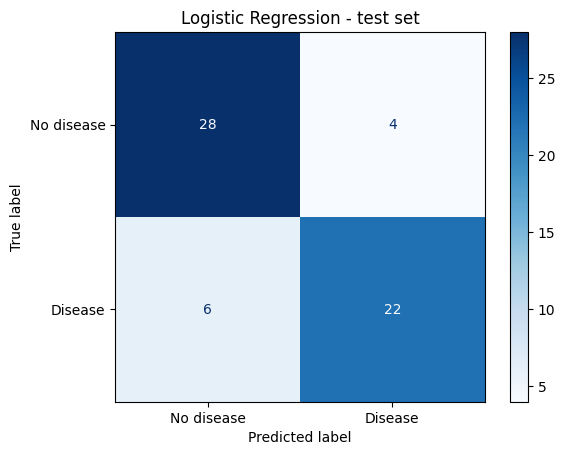

              precision    recall  f1-score   support

  No disease       0.82      0.88      0.85        32
     Disease       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60



In [7]:
pred = lr.predict(X_test_s)
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=["No disease","Disease"]).plot(cmap="Blues")
plt.title("Logistic Regression - test set")
plt.show()
print(classification_report(y_test, pred, target_names=["No disease","Disease"], zero_division=0))

**What the numbers mean:** _(explain in your own words: top-left = true negatives, bottom-right = true positives, top-right = false positives, bottom-left = false negatives. Which error matters more in a medical setting, and why?)_

## 8. 5-fold cross-validation

Logistic Regression: mean=0.825  std=0.032  folds=[0.85  0.867 0.78  0.831 0.797]
Random Forest: mean=0.818  std=0.048  folds=[0.833 0.9   0.78  0.763 0.814]


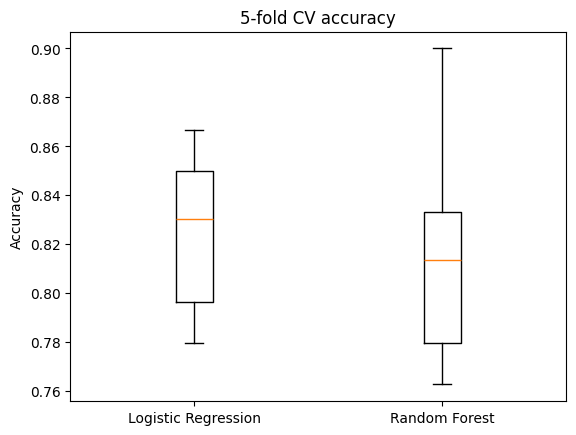

In [8]:
from sklearn.pipeline import make_pipeline
# Pipeline keeps scaling inside each fold (no leakage)
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, random_state=42)),
}
results = {}
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=5, scoring="accuracy")
    results[name] = s
    print(f"{name}: mean={s.mean():.3f}  std={s.std():.3f}  folds={np.round(s,3)}")

plt.boxplot(list(results.values()))
plt.xticks([1, 2], list(results.keys()))
plt.ylabel("Accuracy"); plt.title("5-fold CV accuracy"); plt.show()

## 9. Test on random patients
Patients are drawn from the **test set** only (never seen in training). Run this cell several times for different samples.

In [9]:
sample = X_test.sample(10)
idx = [X_test.index.get_loc(i) for i in sample.index]

check = pd.DataFrame({
    "actual": y_test.iloc[idx].values,
    "LogReg": lr.predict(X_test_s[idx]),
    "RandomForest": rf.predict(X_test_s[idx]),
}, index=sample.index)
check["LogReg_ok"] = check["actual"] == check["LogReg"]
check["RF_ok"] = check["actual"] == check["RandomForest"]
print(check)

     actual  LogReg  RandomForest  LogReg_ok  RF_ok
200       0       0             0       True   True
290       1       1             0       True  False
157       1       1             1       True   True
242       0       0             0       True   True
198       0       0             0       True   True
232       1       1             0       True  False
272       1       1             1       True   True
135       0       0             0       True   True
155       1       1             1       True   True
34        0       0             0       True   True


## 10. Stability across 20 random splits

In [10]:
accs = []
for seed in range(20):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    accs.append(m.score(Xte, yte))
print(f"mean={np.mean(accs):.3f}  std={np.std(accs):.3f}  min={min(accs):.3f}  max={max(accs):.3f}")

mean=0.843  std=0.033  min=0.783  max=0.917


## 11. Save trained models for the web app (HRTGUI.py)

In [11]:
import joblib

final_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, random_state=42)),
}
for m in final_models.values():
    m.fit(X_train, y_train)

accuracy = {n: m.score(X_test, y_test) for n, m in final_models.items()}
joblib.dump({"models": final_models, "X_test": X_test, "y_test": y_test, "accuracy": accuracy},
            "heart_models.joblib")
print("Saved heart_models.joblib", {k: round(v, 3) for k, v in accuracy.items()})

Saved heart_models.joblib {'Logistic Regression': 0.833, 'Random Forest': 0.867}



## 12. Conclusions

- **Model comparison:** On the single test split, Random Forest scored 86.7% and Logistic
  Regression 83.3%. But 5-fold cross-validation gave Logistic Regression 82.5% (±0.032) and
  Random Forest 81.8% (±0.048). That gap of 0.7 points is much smaller than the spread between
  folds, so neither model is clearly better on this dataset.
- **One split is unreliable:** Over 20 random splits, Logistic Regression accuracy ranged from
  78.3% to 91.7% (mean 84.3%). The test set is only 60 patients, so a single number is
  partly luck. I trust the cross-validation result more.
- **Which model I would pick:** Logistic Regression. It performs about the same, it is simpler
  to explain, and it was more stable between folds.
- **Errors matter:** Logistic Regression missed 6 of the 28 patients who had disease (recall
  0.79). In medicine, missing a sick patient is worse than a false alarm.
- **Limits:** Only 297 patients from one hospital, no outside validation, and I simplified the
  target to yes/no. This is a learning project, **not medical advice**.
- **Next steps:** Tune the models, add the other hospital datasets, and optimise for recall.


## 13. (Optional) Quantum comparison


In [ ]:
# 13 Cell 1(Picking 2 Features and scaling them)

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline
import itertools, time

# Pick the 2 best features using TRAINING data only (5-fold CV, simple classical model)
pair_scores = {}
for a, b in itertools.combinations(X.columns, 2):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    pair_scores[(a, b)] = cross_val_score(m, X_train[[a, b]], y_train, cv=5).mean()
q_feats = list(max(pair_scores, key=pair_scores.get))
print("Chosen features:", q_feats, "| CV accuracy:", round(max(pair_scores.values()), 3))

# Scale the two features to angles between 0 and pi (fit on training data only)
q_scaler = MinMaxScaler(feature_range=(0, np.pi)).fit(X_train[q_feats])
Xq_train = q_scaler.transform(X_train[q_feats])
Xq_test = q_scaler.transform(X_test[q_feats])
yq_train, yq_test = y_train.values, y_test.values

Chosen features: ['oldpeak', 'thal'] | CV accuracy: 0.789


In [ ]:
# 13 Cell 2 (building the quantum circuit)

x = ParameterVector("x", 2)   # the 2 patient features
w = ParameterVector("w", 6)   # the 6 trainable weights

qc = QuantumCircuit(2)
for _ in range(2):            # feature map (repeated twice)
    qc.h([0, 1])
    qc.rz(2 * x[0], 0)
    qc.rz(2 * x[1], 1)
    qc.cx(0, 1)
    qc.rz(2 * (np.pi - x[0]) * (np.pi - x[1]), 1)
    qc.cx(0, 1)
qc.ry(w[0], 0); qc.ry(w[1], 1); qc.cx(0, 1)   # trainable layers
qc.ry(w[2], 0); qc.ry(w[3], 1); qc.cx(0, 1)
qc.ry(w[4], 0); qc.ry(w[5], 1)
#print(qc.draw("text"))

     ┌───┐┌────────────┐                                         ┌───┐»
q_0: ┤ H ├┤ Rz(2*x[0]) ├──■───────────────────────────────────■──┤ H ├»
     ├───┤├────────────┤┌─┴─┐┌─────────────────────────────┐┌─┴─┐├───┤»
q_1: ┤ H ├┤ Rz(2*x[1]) ├┤ X ├┤ Rz(2*(π - x[0])*(π - x[1])) ├┤ X ├┤ H ├»
     └───┘└────────────┘└───┘└─────────────────────────────┘└───┘└───┘»
«     ┌────────────┐                                         ┌──────────┐     »
«q_0: ┤ Rz(2*x[0]) ├──■───────────────────────────────────■──┤ Ry(w[0]) ├──■──»
«     ├────────────┤┌─┴─┐┌─────────────────────────────┐┌─┴─┐├──────────┤┌─┴─┐»
«q_1: ┤ Rz(2*x[1]) ├┤ X ├┤ Rz(2*(π - x[0])*(π - x[1])) ├┤ X ├┤ Ry(w[1]) ├┤ X ├»
«     └────────────┘└───┘└─────────────────────────────┘└───┘└──────────┘└───┘»
«     ┌──────────┐     ┌──────────┐
«q_0: ┤ Ry(w[2]) ├──■──┤ Ry(w[4]) ├
«     ├──────────┤┌─┴─┐├──────────┤
«q_1: ┤ Ry(w[3]) ├┤ X ├┤ Ry(w[5]) ├
«     └──────────┘└───┘└──────────┘


In [ ]:

# 13 Cell 3 (Traing the circuit)

def prob_disease(features, weights):
    """Probability of an odd measurement result (01 or 10) = class 'disease'."""
    values = {**dict(zip(x, features)), **dict(zip(w, weights))}
    probs = Statevector(qc.assign_parameters(values)).probabilities()
    return probs[1] + probs[2]

# Train on a balanced subset of 120 training patients to keep it quick
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.where(yq_train == c)[0], 60, replace=False) for c in (0, 1)])
calls, t0 = {"n": 0}, time.time()

def loss(weights):
    p = np.array([prob_disease(f, weights) for f in Xq_train[idx]])
    p = np.clip(p, 1e-6, 1 - 1e-6)
    l = -np.mean(yq_train[idx] * np.log(p) + (1 - yq_train[idx]) * np.log(1 - p))
    calls["n"] += 1
    if calls["n"] % 20 == 0:
        print(f"step {calls['n']:3d}/120   loss = {l:.3f}   ({time.time() - t0:.0f} s)")
    return l

result = minimize(loss, rng.uniform(0, 2 * np.pi, 6), method="COBYLA", options={"maxiter": 120})
print("Training finished in", round(time.time() - t0), "s. Final loss:", round(result.fun, 3))

step  20/120   loss = 0.540   (3 s)
step  40/120   loss = 0.529   (5 s)
step  60/120   loss = 0.526   (8 s)
step  80/120   loss = 0.522   (10 s)
step 100/120   loss = 0.514   (13 s)
step 120/120   loss = 0.511   (15 s)
Training finished in 15 s. Final loss: 0.511


Quantum (2 qubits)       0.783
Logistic Regression      0.767
Random Forest            0.767
Always guess majority    0.533
dtype: float64


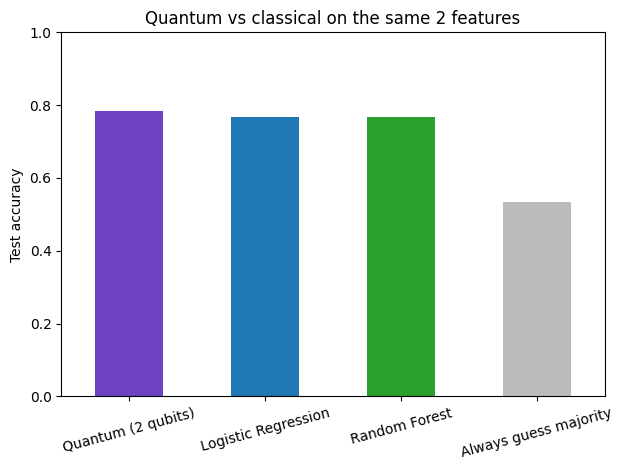

In [16]:
# 13 Cell 4 (comparing with the classical models)

q_pred = np.array([prob_disease(f, result.x) >= 0.5 for f in Xq_test]).astype(int)

# Classical models on the SAME two features
lr2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train[q_feats], y_train)
rf2 = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, random_state=42)).fit(X_train[q_feats], y_train)

comparison = pd.Series({
    "Quantum (2 qubits)": (q_pred == yq_test).mean(),
    "Logistic Regression": lr2.score(X_test[q_feats], y_test),
    "Random Forest": rf2.score(X_test[q_feats], y_test),
    "Always guess majority": max(yq_test.mean(), 1 - yq_test.mean()),
})
print(comparison.round(3))
comparison.plot(kind="bar", rot=15, ylim=(0, 1), color=["#6f42c1", "#1f77b4", "#2ca02c", "#bbbbbb"])
plt.ylabel("Test accuracy")
plt.title("Quantum vs classical on the same 2 features")
plt.tight_layout(); plt.show()

In [17]:
# 13 Cell 5 (Testing random test patients, quantum vs real answer)

pick = np.random.choice(len(Xq_test), 10, replace=False)
table = pd.DataFrame({
    "actual": yq_test[pick],
    "quantum": [int(prob_disease(Xq_test[i], result.x) >= 0.5) for i in pick],
    "disease_prob": [round(prob_disease(Xq_test[i], result.x), 3) for i in pick],
})
table["correct"] = table["actual"] == table["quantum"]
print(table)
print("Correct:", int(table["correct"].sum()), "of 10")

   actual  quantum  disease_prob  correct
0       1        0         0.240    False
1       1        0         0.344    False
2       0        0         0.289     True
3       0        0         0.289     True
4       1        1         0.849     True
5       1        1         0.927     True
6       0        0         0.289     True
7       0        0         0.171     True
8       0        0         0.257     True
9       0        0         0.289     True
Correct: 8 of 10


In [18]:
# 13 Cell 6 (Testing random test patients, quantum vs real answer)

my_patient = {"oldpeak": 2.5, "thal": 7}

row = pd.DataFrame([my_patient])[q_feats]
angles = q_scaler.transform(row)[0]
p = prob_disease(angles, result.x)
print(f"Quantum model: {p:.1%} chance of disease ->",
      "disease likely" if p >= 0.5 else "no disease predicted")


Quantum model: 89.2% chance of disease -> disease likely
